# [기초-실습] 통계 101×데이터 분석: (7장) 상관과 회귀

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [1]:
# # 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# # 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
# !pip install statsmodels
# !sudo apt-get install -y fonts-nanum
# !sudo fc-cache -fv
# !rm ~/.cache/matplotlib -rf

### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `smf`는 회귀식을 `'y ~ x'` 형태로 쓰는 모듈, `het_breuschpagan`은 등분산 검정 함수입니다.

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 문제 1 · 펭귄의 부리는 길수록 두꺼울까?

`난이도 하` · `예상 15분`

**📖 상황**

- 남극 팔머 기지에서 측정한 펭귄 344마리의 신체 데이터(`penguins`)를 사용합니다.

- 부리 길이(`bill_length_mm`)와 부리 두께(`bill_depth_mm`)가 함께 어떻게 움직이는지 봅니다.

- 그런데 이 데이터에는 **세 종(Adelie·Chinstrap·Gentoo)이 섞여 있습니다.**
  전체를 뭉쳐서 볼 때와 집단을 나눠서 볼 때 **결론이 정반대로 뒤집히는 일**이 실제로 일어납니다.

**🎯 이 문제로 배우는 것**

- 상관계수를 계산하기 **전에** 산점도를 먼저 그려야 하는 이유를, 숫자로 직접 확인합니다.

In [3]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


### Q1 · 산점도로 두 변수의 관계를 그려 봅시다

- 가로축 `bill_length_mm`, 세로축 `bill_depth_mm`로 산점도를 그리세요.

- 그래프 제목과 축 라벨을 한글로 알아보기 쉽게 설정하세요.

- `💡 힌트` `sns.scatterplot(data=..., x=..., y=...)` / `plt.title()`, `plt.xlabel()`, `plt.ylabel()`

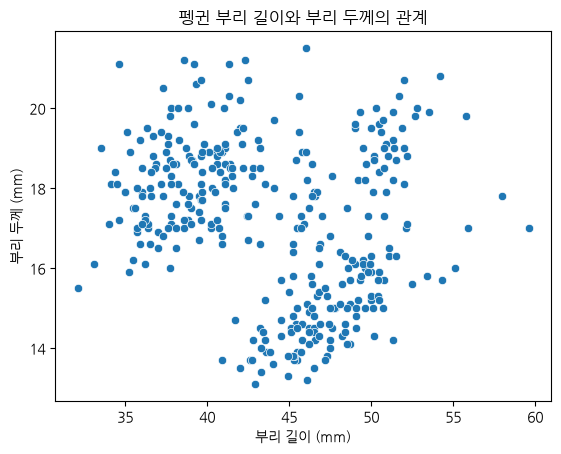

In [4]:
# 문제 1 · Q1
import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')

plt.title('펭귄 부리 길이와 부리 두께의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q2 · 종별로 색을 나눠 같은 그림을 다시 그려 봅시다

- Q1과 똑같은 산점도에 펭귄의 종(`species`)별로 점의 색을 다르게 칠하세요.

- Q1의 그림과 나란히 놓고 무엇이 달라 보이는지 관찰하세요.

- `💡 힌트` `sns.scatterplot()`에 `hue` 인수를 추가해 보세요.

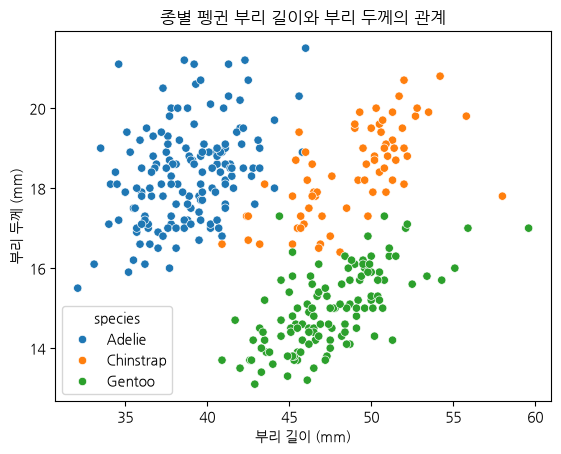

In [5]:
# 문제 1 · Q2
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')

plt.title('종별 펭귄 부리 길이와 부리 두께의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q3 · 상관계수를 '전체'와 '종별'로 각각 구해 비교해 봅시다

- 두 변수의 상관계수를 **전체 데이터**에 대해 계산하세요.

- 같은 상관계수를 **종별로 나누어** 계산하세요.

- 두 결과의 **부호**를 비교하세요.

- `💡 힌트` 전체는 `df[['A','B']].dropna().corr()`,
  종별은 `df.groupby('species')[['A','B']].corr()`를 활용해 보세요.

In [6]:
# 문제 1 · Q3
cols = ['bill_length_mm', 'bill_depth_mm']

# 1) 전체
print("=== 전체 ===")
print(penguins[cols].dropna().corr())

# 2) 종별
print("\n=== 종별 ===")
print(penguins.groupby('species')[cols].corr())

=== 전체 ===
                bill_length_mm  bill_depth_mm
bill_length_mm        1.000000      -0.235053
bill_depth_mm        -0.235053       1.000000

=== 종별 ===
                          bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000


### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유**를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 부호가 뒤집히는 열쇠는 **종마다 부리의 '기본 크기'가 다르다**는 데 있습니다. 종별 평균이 어디에 놓여 있는지를 Q2의 그림에서 확인해 보세요.

- "전체를 보면 음, 나누면 양"은 두 변수 사이에 **숨은 집단 변수**가 끼어 있을 때 나타납니다. 이 현상에는 이름이 붙어 있고, 다음 시간 인과추론에서 다시 만납니다.

- 결론의 형태를 이렇게 나눠 써 보면 정확해집니다 — "종을 무시하면 ○○, 종을 고려하면 ○○".

</details>

### 💬 정리 · 결과를 말로 설명해 보기

**1. Q1 산점도의 방향과 Q3 전체 상관계수의 부호**

- Q1 산점도는 세 덩어리로 나뉘어 있어 뚜렷한 방향은 없었지만, 전체적으로 **약하게 오른쪽 아래로(↘)** 내려가는 모습이었다.
- Q3의 전체 상관계수는 **r = −0.24**로, 산점도에서 본 방향과 **부호가 일치**한다.
- 다만 절댓값이 작아 **약한 음의 상관**이다.

**2. 종별 상관계수와 전체 상관계수의 부호 비교**

| 구분 | 상관계수 r | 부호 |
|---|---|---|
| 전체 | −0.24 | − |
| Adelie | +0.39 | + |
| Chinstrap | +0.65 | + |
| Gentoo | +0.64 | + |

- 종별로는 **세 종 모두 양수**로, 전체와 **부호가 반대**다.

**3. 같은 데이터인데 결론이 정반대로 나온 이유**

- 종마다 부리의 **기본 크기가 다르기** 때문이다.
  - Adelie: 부리가 **짧고 두꺼움** → 그래프 왼쪽 위
  - Gentoo: 부리가 **길고 얇음** → 그래프 오른쪽 아래
- 각 종 **안에서는** 부리가 길수록 두꺼워지지만(↗), 세 종을 섞으면 왼쪽 위 무리와 오른쪽 아래 무리를 잇는 방향(↘)이 더 크게 드러난다.
- 이 착시를 만드는 것은 **종(species)이라는 숨은 집단 변수**이며, 이러한 현상을 **심슨의 역설(Simpson's Paradox)** 이라고 한다.

**4. '종' 정보가 없었다면 내렸을 잘못된 결론**

- **종을 무시하면** → "펭귄은 부리가 길수록 얇아진다"는 잘못된 결론을 내린다.
- **종을 고려하면** → "같은 종 안에서는 부리가 길수록 두꺼워진다"가 올바른 결론이다.
- 종 정보가 없었다면 이 오류를 알아챌 방법이 없었을 것이다.

**✅ 배운 점**

- 상관계수를 계산하기 **전에 반드시 산점도를 먼저** 그려 데이터의 모양을 확인해야 한다.
- 데이터 안에 **숨은 집단**이 있는지 확인하고, 필요하면 **집단별로 나누어** 분석해야 한다.

## 문제 2 · 날개가 길면 몸무게도 무거울까? — 관계를 숫자로

`난이도 하` · `예상 20분`

**📖 상황**

- 문제 1에서 "숫자 전에 그림"을 배웠습니다. 이제 관계를 **숫자 하나**로 요약해 봅니다.

- 이번에는 **날개 길이(`flipper_length_mm`)와 몸무게(`body_mass_g`)**를 봅니다.
  이 두 변수는 **문제 5까지 계속 사용**하며, 상관 → 회귀 → 검정 → 진단으로 이어집니다.

- **피어슨 상관계수(r)**는 관계의 방향(부호)과 강도(절대값)를 −1~+1로 나타냅니다.
  다만 피어슨은 **두 변수가 정규분포라는 전제**에 기대는 모수적 방법입니다.

**🎯 이 문제로 배우는 것**

- 정규성 점검 → 피어슨(r과 p-값) → 스피어만 비교의 순서로, **강의에서 배운 절차 그대로** 상관을 구합니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


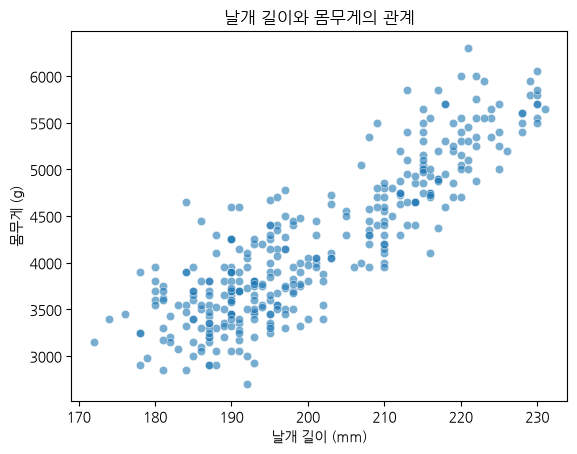

In [7]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### Q1 · 피어슨의 전제인 정규성을 점검해 봅시다

- `flipper_length_mm`과 `body_mass_g` **각각**에 대해 정규성 검정(Shapiro-Wilk)을 수행하세요.

- 유의수준 0.05를 기준으로 '정규성을 기각하는지'까지 함께 출력하세요.

- `💡 힌트` `stats.shapiro(데이터)`는 통계량과 p-값을 함께 돌려줍니다.

In [8]:
# 문제 2 · Q1
from scipy import stats

cols = ['flipper_length_mm', 'body_mass_g']

for col in cols:
    data = penguins[col].dropna()          # 빈 값 빼기
    w, p = stats.shapiro(data)             # 정규성 검정

    print(f"[{col}]")
    print(f"  W = {w:.4f}, p-value = {p:.2e}")

    if p < 0.05:
        print("  → p < 0.05 : 정규성 기각 (정규분포 아님)")
    else:
        print("  → p ≥ 0.05 : 정규성 기각 못 함 (정규분포로 볼 수 있음)")

[flipper_length_mm]
  W = 0.9515, p-value = 3.54e-09
  → p < 0.05 : 정규성 기각 (정규분포 아님)
[body_mass_g]
  W = 0.9592, p-value = 3.68e-08
  → p < 0.05 : 정규성 기각 (정규분포 아님)


### Q2 · 피어슨 상관계수와 p-값을 함께 구해 봅시다

- 상관계수만이 아니라 **p-값도 함께** 구하세요. 상관계수도 가설검정의 대상입니다.

- 결과는 반드시 `r`, `p_value`라는 이름으로 저장하세요. **문제 3·4에서 이어서 사용합니다.**

- `💡 힌트` `r, p_value = stats.pearsonr(x, y)` — 귀무가설은 "모집단의 상관계수가 0이다"입니다.

In [9]:
# 문제 2 · Q2
from scipy import stats

# 두 열을 함께 꺼내서 빈 값이 있는 줄 통째로 빼기
data = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

x = data['flipper_length_mm']
y = data['body_mass_g']

r, p_value = stats.pearsonr(x, y)

print(f"피어슨 상관계수 r = {r:.4f}")
print(f"p-value = {p_value:.2e}")

if p_value < 0.05:
    print("→ p < 0.05 : 귀무가설 기각 (상관관계가 통계적으로 유의함)")
else:
    print("→ p ≥ 0.05 : 귀무가설 기각 못 함 (유의하지 않음)")

피어슨 상관계수 r = 0.8712
p-value = 4.37e-107
→ p < 0.05 : 귀무가설 기각 (상관관계가 통계적으로 유의함)


① 펭귄 날개 길이 vs 몸무게: 피어슨 r = 0.87, 스피어만 ρ = 0.84
② 튀는 값(이상치) 하나: 피어슨 r = 0.77, 스피어만 ρ = 0.24
③ 계속 오르지만 휘어진 곡선: 피어슨 r = 0.77, 스피어만 ρ = 0.91


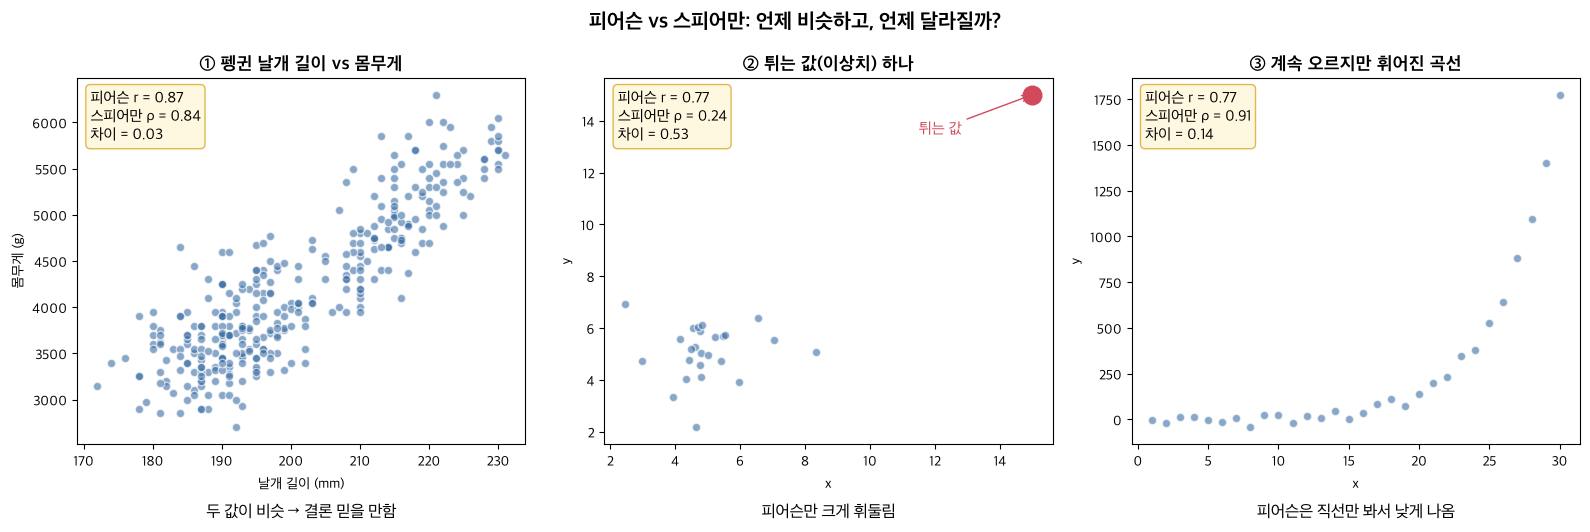

In [10]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

# 한글 폰트 설정 (Mac) - 굵은 글씨도 지원하는 폰트
plt.rc('font', family='Apple SD Gothic Neo')
plt.rc('axes', unicode_minus=False)

rng = np.random.default_rng(3)

# ① 펭귄 데이터: 날개 길이 vs 몸무게
data_tmp = penguins[['flipper_length_mm', 'body_mass_g']].dropna()
x1 = data_tmp['flipper_length_mm'].values
y1 = data_tmp['body_mass_g'].values

# ② 관계없는 점 25개 + 튀는 값 1개
x2 = rng.normal(5, 1, 25)
y2 = rng.normal(5, 1, 25)
x2 = np.append(x2, 15)
y2 = np.append(y2, 15)

# ③ 계속 오르지만 휘어진 곡선
x3 = np.arange(1, 31)
y3 = np.exp(x3 / 4) + rng.normal(0, 20, 30)

cases = [
    (x1, y1, '① 펭귄 날개 길이 vs 몸무게', '두 값이 비슷 → 결론 믿을 만함', '날개 길이 (mm)', '몸무게 (g)'),
    (x2, y2, '② 튀는 값(이상치) 하나', '피어슨만 크게 휘둘림', 'x', 'y'),
    (x3, y3, '③ 계속 오르지만 휘어진 곡선', '피어슨은 직선만 봐서 낮게 나옴', 'x', 'y'),
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5.5))

for i, (ax, (xx, yy, title, note, xlabel, ylabel)) in enumerate(zip(axes, cases)):
    r_tmp = stats.pearsonr(xx, yy)[0]       # 피어슨 r
    rho_tmp = stats.spearmanr(xx, yy)[0]    # 스피어만 ρ

    ax.scatter(xx, yy, alpha=0.6, color='#3b6ea5', edgecolor='white')

    # ② 그래프에만 튀는 값 강조
    if i == 1:
        ax.scatter([15], [15], s=180, color='#d1495b', zorder=3)
        ax.annotate('튀는 값', xy=(15, 15), xytext=(11.5, 13.5),
                    fontsize=11, color='#d1495b',
                    arrowprops=dict(arrowstyle='->', color='#d1495b'))

    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)

    # 왼쪽 위에 r, ρ 값 표시
    ax.text(0.03, 0.97,
            f'피어슨 r = {r_tmp:.2f}\n스피어만 ρ = {rho_tmp:.2f}\n차이 = {abs(r_tmp - rho_tmp):.2f}',
            transform=ax.transAxes, va='top', fontsize=11,
            bbox=dict(boxstyle='round', fc='#fff8e1', ec='#e0b84c'))

    # 그래프 아래 설명
    ax.text(0.5, -0.2, note, transform=ax.transAxes, ha='center', fontsize=12)

    print(f'{title}: 피어슨 r = {r_tmp:.2f}, 스피어만 ρ = {rho_tmp:.2f}')

plt.suptitle('피어슨 vs 스피어만: 언제 비슷하고, 언제 달라질까?', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

### Q3 · 스피어만 상관계수를 구해 피어슨과 비교해 봅시다

- 스피어만 상관계수(ρ)를 구하세요.

- Q2의 피어슨 값과 **나란히 출력**해 두 값의 차이를 눈으로 확인하세요.

- `💡 힌트` `stats.spearmanr(x, y)`

In [11]:
# 문제 2 · Q3
rho, p_spearman = stats.spearmanr(x, y)

print(f"{'방법':<10}{'상관계수':>10}{'p-value':>15}")
print(f"{'피어슨 r':<10}{r:>10.4f}{p_value:>15.2e}")
print(f"{'스피어만 ρ':<10}{rho:>10.4f}{p_spearman:>15.2e}")
print(f"\n두 값의 차이 = {r - rho:.4f}")

방법              상관계수        p-value
피어슨 r         0.8712      4.37e-107
스피어만 ρ        0.8400       2.76e-92

두 값의 차이 = 0.0312


### Q4 · 세 결과를 종합해 관계를 문장으로 정리해 봅시다

- Q1~Q3의 결과를 근거로, 오른쪽 빈칸을 채워 관계를 정리하세요.

- 숫자만 적지 말고 **그 숫자가 뜻하는 바**를 함께 쓰세요.

문제 2 · Q4
정규성 검정 결과 (피어슨의 전제가 지켜졌나요?):
  날개 길이 W=0.9515, p=3.54e-09 / 몸무게 W=0.9592, p=3.68e-08
  → 두 변수 모두 p < 0.05라서 정규성이 기각됨. 피어슨의 전제(정규분포)는 지켜지지 않았다.
  → 여러 종이 섞여 봉우리가 여러 개인 분포가 된 것으로 보인다.

피어슨 r 값과 p-값:
  r = 0.8712, p = 4.37e-107
  → p < 0.05라서 "모집단 상관계수 = 0"이라는 귀무가설을 기각. 관계는 통계적으로 유의하다.
  → 다만 정규성 전제가 깨졌으므로 이 p값은 조심해서 해석해야 한다.

스피어만 ρ 값:
  ρ = 0.8400, p = 2.76e-92
  → 정규성 가정 없이 순위로 계산해도 피어슨과 거의 같은 값(차이 약 0.03)이 나왔다.
  → 따라서 "강한 양의 상관"이라는 결론은 믿을 만하다.

부호(+/-)가 뜻하는 관계의 방향:
  r, ρ 모두 + → 날개 길이가 길수록 몸무게도 무거워지는 '양의 상관'이다.

절대값의 크기가 뜻하는 관계의 강도:
  r = 0.87, ρ = 0.84로 1에 가까움 → 두 변수는 '강한' 상관관계를 가진다.
  (단, 상관일 뿐 날개가 길어서 무거워진다는 인과관계를 뜻하지는 않는다.)

### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 정규성이 기각되었습니다. 그렇다면 피어슨 상관계수를 쓰면 안 되는 걸까요? Q2와 Q3의 값을 비교해서 판단해 보세요.

- 피어슨과 스피어만이 비슷하게 나왔다는 것은 무엇을 뜻할까요? 만약 두 값이 크게 달랐다면 어떤 상황을 의심해야 할까요?

- Q2의 p-값은 무엇에 대한 검정인가요? "상관계수가 크다"와 "상관계수가 유의하다"는 같은 말인가요?

- '날개가 길어지는 것이 몸무게를 무겁게 만드는 **원인**이다'라고 결론 내릴 수 있을까요? **교란변수 / 역인과 / 우연** 세 가지로 나누어 설명해 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 정규성이 깨졌을 때 확인할 것은 "쓰면 안 되나"가 아니라 **"결론이 바뀌는가"**입니다. 두 계수가 거의 같다면 전제 위배의 영향이 작다는 뜻이고, 크게 다르면 이상치나 비선형을 의심합니다.

- p-값은 관계의 **크기**가 아니라 **존재**에 대한 답입니다. 표본이 커지면 아주 작은 상관도 유의해집니다 — 두 질문을 분리해서 답해 보세요.

- 인과를 부정하는 세 갈래를 이 데이터에 대입해 보세요. 교란변수 후보는 문제 1에서 이미 만났습니다.

</details>

### 💬 정리 · 결과를 말로 설명해 보기

**1. 정규성이 기각되었으면 피어슨 상관계수를 쓰면 안 될까?**

- 정규성이 깨졌을 때 중요한 것은 "쓰면 안 되는가"가 아니라 **"결론이 바뀌는가"**이다.
- 피어슨 r = 0.87, 스피어만 ρ = 0.84로 **차이가 약 0.03에 불과**하다.
- 정규성 가정이 필요 없는 스피어만으로 계산해도 "강한 양의 상관"이라는 결론이 같으므로, **정규성 위배가 결론에 미친 영향은 작다.**
- 따라서 피어슨 결과를 참고할 수는 있지만, 전제가 깨졌으므로 **스피어만 결과를 함께 보고하는 것**이 안전하다.

**2. 피어슨과 스피어만이 비슷하다는 것의 의미 / 크게 달랐다면?**

- 두 값이 비슷하다는 것은 **실제 값으로 계산하든 순위로 계산하든 관계가 같다**는 뜻이다. 즉, 결과를 크게 왜곡하는 이상치나 휘어진 관계가 없다고 볼 수 있다.
- 만약 두 값이 크게 달랐다면 다음을 의심해야 한다.
  - **이상치(튀는 값)**: 피어슨은 실제 값을 쓰기 때문에 튀는 값 하나에 크게 휘둘리지만, 스피어만은 순위만 보기 때문에 영향을 덜 받는다.
  - **비선형 관계**: 계속 증가하지만 곡선으로 휘어진 관계라면 스피어만은 높게, 피어슨은 낮게 나올 수 있다.
  - **여러 집단이 섞임**: 문제 1의 펭귄 부리처럼 숨은 집단이 결과를 왜곡할 수 있다.
- 이럴 때는 **산점도를 다시 그려** 원인을 확인해야 한다.

**3. Q2의 p-값은 무엇에 대한 검정인가? "크다"와 "유의하다"는 같은 말인가?**

- Q2의 p-값은 **"모집단의 상관계수가 0이다(관계가 없다)"**라는 귀무가설에 대한 검정이다.
  즉, 관계가 없는데도 이런 결과가 **우연히** 나올 확률이다.
- **"상관계수가 크다"와 "상관계수가 유의하다"는 다른 말이다.**
  - **크다** → 관계의 **강도** (r의 크기로 판단)
  - **유의하다** → 관계의 **존재** 여부 (p-값으로 판단)
- 표본 크기 n이 크면 아주 작은 상관도 유의해질 수 있다.
  예) r = 0.25일 때 n = 30이면 p ≈ 0.18(유의하지 않음), n = 100이면 p ≈ 0.01(유의함)
- 이번 데이터는 r = 0.87(**강함**)이고 p = 4.37e-107(**유의함**)로, 두 질문 모두에 "그렇다"고 답할 수 있다.

**4. '날개가 길어지는 것이 몸무게를 무겁게 만드는 원인이다'라고 할 수 있을까?**

- **할 수 없다.** 상관관계만으로는 인과관계를 증명할 수 없다.

| 갈래 | 설명 |
|---|---|
| **교란변수** | 날개 길이와 몸무게 **둘 다에 영향을 주는 제3의 요인**이 있을 수 있다. 대표적으로 **종(species)**이다. Gentoo는 원래 덩치가 커서 날개도 길고 몸무게도 무겁다. 이 밖에 **성별**, **나이(성장 정도)** 등도 후보다. |
| **역인과** | 방향이 반대일 수도 있다. 몸이 무거운 펭귄일수록 헤엄치고 몸을 지탱하기 위해 **날개가 길게 발달**했을 수 있다. 데이터만으로는 어느 쪽이 원인인지 알 수 없다. |
| **우연** | p = 4.37e-107로 매우 작아서 **우연일 가능성은 사실상 없다.** 다만 이 데이터는 남극 팔머 기지 주변 펭귄에서만 측정한 것이므로, 다른 지역 펭귄에게도 그대로 적용된다고 일반화하기는 어렵다. |

- 인과를 확인하려면 **종·성별 같은 교란변수를 함께 넣은 다중회귀**로 분석하거나, 다른 조건이 같은 상태에서 비교해야 한다.

**✅ 배운 점**

- 전제가 깨졌을 때는 **다른 방법(스피어만)으로도 결론이 같은지** 확인한다.
- **크기(r)와 유의성(p)은 따로** 판단해야 한다.
- 강하고 유의한 상관이라도 **인과관계를 뜻하지는 않는다.**

## 문제 3 · 그 관계를 하나의 식으로 만들 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 상관계수는 "관계가 얼마나 **강한가**"만 알려주고, "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는
  말해주지 않습니다. 그 답을 주는 것이 **선형회귀(Linear Regression)**입니다.

- 흩어진 점들을 가장 잘 가로지르는 직선 `y = a + bx`를 찾아 관계를 하나의 **식**으로 표현합니다.
  `a`(절편)는 x가 0일 때의 예측값, `b`(기울기)는 **x가 1 늘 때 y가 평균적으로 변하는 양**입니다.

- 그런데 상관과 회귀는 **서로 남이 아닙니다.** 문제 2에서 구한 `r`과
  이번에 구할 기울기·결정계수 사이에는 정확한 관계식이 성립합니다.

**🎯 이 문제로 배우는 것**

- 회귀식을 적합·해석하고, **상관과 회귀가 한 뿌리임을 숫자로 확인**합니다.

In [12]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### Q1 · 단순회귀 모델을 적합해 봅시다

- **날개 길이(설명변수) → 몸무게(반응변수)** 회귀 모델을 적합하세요.

- 적합한 모델은 반드시 `model`이라는 이름으로 저장하세요. **문제 4·5에서 이어서 사용합니다.**

- `💡 힌트` `model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=...).fit()`

In [13]:
# 문제 3 · Q1
import statsmodels.formula.api as smf

model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=df_corr).fit()

print(model.params)        # a(절편), b(기울기)
print("R² =", model.rsquared)

Intercept           -5780.831358
flipper_length_mm      49.685566
dtype: float64
R² = 0.7589925193571176


### Q2 · 분석 결과표를 출력해 봅시다

- 적합한 모델의 요약 결과표를 출력하세요.

- `coef`, `P>|t|`, `R-squared` 열이 각각 어디에 있는지 눈으로 찾아 두세요. 다음 문제들에서 계속 씁니다.

- `💡 힌트` 모델 객체의 `.summary()` 메소드를 사용하세요.

In [14]:
# 문제 3 · Q2
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        17:50:07   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### 📌 회귀 결과표(summary)에서 꼭 찾아둘 3개

| 번호 | 이름 | 위치 | 값 | 뜻 | 연결 개념 |
|---|---|---|---|---|---|
| ① | **coef** (코에프) | 아래 표 첫 번째 열 | a = −5780.83<br>**b = 49.69** | 회귀식의 절편(a)과 기울기(b)<br>→ 날개가 1mm 길면 몸무게가 평균 49.69g 증가 | 7.3-① 회귀계수 |
| ② | **P>\|t\|** (피 값) | 아래 표 가운데 | 0.000 | "b = 0(관계 없음)"이라는 귀무가설에 대한 p값<br>→ 0.05보다 작으므로 기울기는 통계적으로 유의함 | 7.3-③ 회귀계수 검정 |
| ③ | **R-squared** (알 스퀘어드) | 위쪽 오른편 | 0.759 | 결정계수<br>→ 이 직선이 몸무게 차이의 약 76%를 설명함 | 7.3-② 결정계수 |

> 💡 **P>|t| = 0.000**은 진짜 0이 아니라 너무 작아서 소수점 3자리로 표시되지 않는 것 (실제 값 4.37e-107)
>
> 💡 `flipper_length_mm` 줄 = **b(기울기)** 관련 숫자, `Intercept` 줄 = **a(절편)** 관련 숫자

### Q3 · 회귀식을 완성해 봅시다

- Q2의 결과표에서 **절편**과 **기울기**를 찾아 오른쪽 빈칸을 채우세요.

- 숫자를 옮겨 적은 뒤, 완성된 식을 한 줄로 써 보세요.

문제 3 · Q3     
절편(a) 값: -5780.83    
기울기(b) 값: 49.69     
완성된 회귀식 → 몸무게(g) = -5780.83 + 49.69 × 날개길이(mm) 

### Q4 · 회귀식으로 예측해 봅시다

- 날개 길이가 평균보다 **10mm 더 긴** 펭귄은, 평균적인 펭귄보다 몸무게가 몇 g 더 무거울까요?

- 계산 결과를 단위(g)와 함께 출력하세요.

- `💡 힌트` 기울기 × 10

In [15]:
# 문제 3 · Q4
b = model.params['flipper_length_mm']   # 기울기 b 꺼내기

diff = b * 10

print(f"날개가 10mm 더 길면 몸무게는 약 {diff:.2f} g 더 무겁다")

날개가 10mm 더 길면 몸무게는 약 496.86 g 더 무겁다


### Q5 · 상관과 회귀를 잇는 두 관계식을 확인해 봅시다

- 다음 두 식이 실제로 성립하는지 **숫자로** 확인하세요.
  - ① 기울기 = `r` × (y의 표준편차 / x의 표준편차)
  - ② 결정계수 `R²` = `r²` _(단순회귀에서만 성립)_

- 좌변과 우변을 **나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` 문제 2 Q2의 `r`을 사용합니다. 표준편차는 `.std(ddof=1)`, 모델의 R²는 `model.rsquared`입니다.

In [16]:
# 문제 3 · Q5
x = df_corr['flipper_length_mm']
y = df_corr['body_mass_g']

sd_x = x.std(ddof=1)   # 날개 길이의 표준편차
sd_y = y.std(ddof=1)   # 몸무게의 표준편차

# ① 기울기 = r × (y 표준편차 / x 표준편차)
b_model = model.params['flipper_length_mm']
b_calc = r * (sd_y / sd_x)

print("① 기울기")
print(f"   모델 기울기          = {b_model:.4f}")
print(f"   r × (sd_y / sd_x)    = {b_calc:.4f}")

# ② R² = r²
print("\n② 결정계수")
print(f"   모델 R²              = {model.rsquared:.4f}")
print(f"   r²                   = {r**2:.4f}")

① 기울기
   모델 기울기          = 49.6856
   r × (sd_y / sd_x)    = 49.6856

② 결정계수
   모델 R²              = 0.7590
   r²                   = 0.7590


findfont: Failed to find font weight bold for AppleGothic, now using 400.
findfont: Failed to find font weight bold for AppleGothic, now using 400.


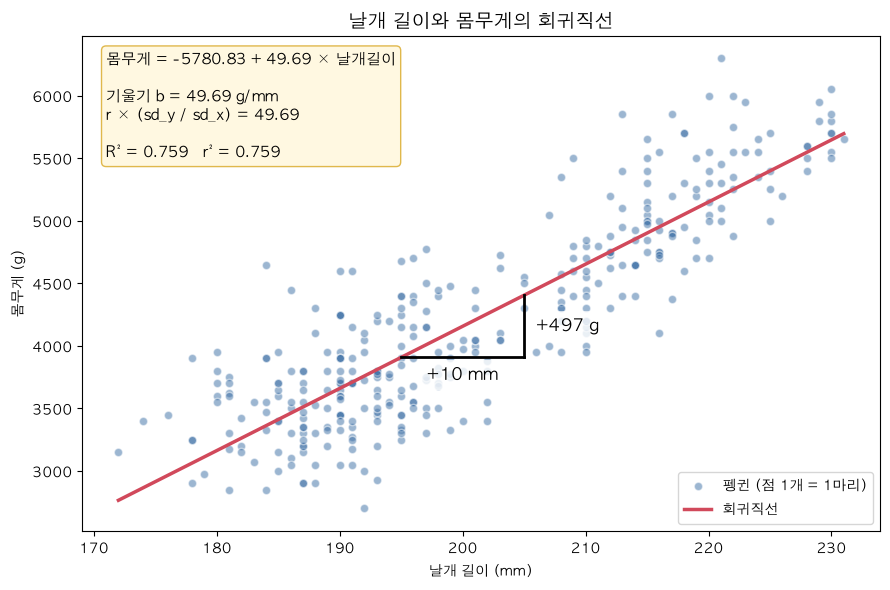

In [17]:
import numpy as np
import matplotlib.pyplot as plt

# 한글 폰트 (Mac)
plt.rc('font', family='AppleGothic')
plt.rc('axes', unicode_minus=False)

x = df_corr['flipper_length_mm']
y = df_corr['body_mass_g']
a = model.params['Intercept']           # 절편
b = model.params['flipper_length_mm']   # 기울기

fig, ax = plt.subplots(figsize=(9, 6))

# 1) 산점도
ax.scatter(x, y, alpha=0.5, color='#3b6ea5', edgecolor='white', label='펭귄 (점 1개 = 1마리)')

# 2) 회귀직선
x_line = np.linspace(x.min(), x.max(), 100)
ax.plot(x_line, a + b * x_line, color='#d1495b', linewidth=2.5, label='회귀직선')

# 3) 기울기 계단: 195mm → 205mm (10mm 늘 때 몸무게 변화)
x0, x1 = 195, 205
y0, y1 = a + b * x0, a + b * x1
ax.plot([x0, x1], [y0, y0], color='black', linewidth=2)   # 가로 (+10mm)
ax.plot([x1, x1], [y0, y1], color='black', linewidth=2)   # 세로 (+497g)

label_box = dict(boxstyle='round', fc='white', ec='none', alpha=0.8)
ax.text((x0 + x1) / 2, y0 - 180, '+10 mm', ha='center', fontsize=12, fontweight='bold', bbox=label_box)
ax.text(x1 + 1, (y0 + y1) / 2, f'+{b * 10:.0f} g', va='center', fontsize=12, fontweight='bold', bbox=label_box)

# 4) 왼쪽 위 설명 상자: 회귀식 + 두 관계식 확인
ax.text(0.03, 0.97,
        f'몸무게 = {a:.2f} + {b:.2f} × 날개길이\n\n'
        f'기울기 b = {b:.2f} g/mm\n'
        f'r × (sd_y / sd_x) = {r * y.std(ddof=1) / x.std(ddof=1):.2f}\n\n'
        f'R² = {model.rsquared:.3f}   r² = {r**2:.3f}',
        transform=ax.transAxes, va='top', fontsize=11,
        bbox=dict(boxstyle='round', fc='#fff8e1', ec='#e0b84c'))

ax.set_title('날개 길이와 몸무게의 회귀직선', fontsize=14, fontweight='bold')
ax.set_xlabel('날개 길이 (mm)')
ax.set_ylabel('몸무게 (g)')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 💬 정리 · 결과를 말로 설명해 보기

- 기울기(b) 값을 "날개 길이가 ○○할 때 몸무게가 ○○한다"는 문장으로 풀어 써 보세요.

- 절편(a)이 음수로 나왔습니다. 이 숫자를 "날개 길이가 0mm인 펭귄의 몸무게"로 해석해도 될까요? 왜 그럴까요?

- Q5에서 `R² = r²`을 확인했습니다. 그렇다면 설명변수와 반응변수를 서로 바꿔 분석하면 **기울기**와 **R²**는 각각 같을까요, 다를까요?

- 상관계수 `r`은 단위 없는 −1~1 값이고, 기울기 `b`는 'mm당 g'이라는 단위를 가집니다. 회귀가 상관보다 더 알려주는 것은 무엇인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 절편은 **데이터가 존재하는 범위 밖의 값**입니다. 날개 길이 0mm인 펭귄은 우리 데이터에 없습니다 — 회귀식은 관측 범위 안에서만 의미를 갖습니다.

- x와 y를 바꿨을 때를 생각할 때 기준은 **"r은 대칭인가, s_y/s_x는 대칭인가"**입니다. 두 관계식 ①②를 각각 대입해 보면 답이 갈립니다.

- "강도"와 "변화량"의 차이로 정리해 보세요. 보고서에 "1mm당 ○g"을 쓸 수 있는 쪽은 어느 것인가요?

</details>

### 💬 정리 · 결과를 말로 설명해 보기

**1. 기울기(b)를 문장으로 풀어 쓰기**

- 기울기 b = 49.69 g/mm
- **날개 길이가 1mm 길어질 때, 몸무게는 평균적으로 약 49.69g 무거워진다.**
- 예를 들어 날개가 10mm 더 긴 펭귄은 평균적으로 약 497g(약 0.5kg) 더 무겁다고 예측된다.
- 단, 이는 "평균적으로 그렇다"는 경향이며, 모든 펭귄이 정확히 그만큼 무겁다는 뜻은 아니다.

**2. 절편(a = −5780.83)을 "날개 0mm인 펭귄의 몸무게"로 해석해도 될까?**

- **해석하면 안 된다.**
- 몸무게가 −5780g이라는 것은 현실적으로 불가능하다.
- 우리 데이터의 날개 길이는 **약 170~230mm 범위**에만 있고, 날개 길이가 0mm인 펭귄은 데이터에 없다.
- 회귀식은 **관측된 데이터 범위 안에서만 의미**를 가진다. 범위 밖으로 넓혀 예측하면 엉뚱한 값이 나올 수 있다.
- 절편은 직선의 위치를 정하기 위한 **계산상의 출발점**일 뿐이다.

**3. 설명변수와 반응변수를 바꾸면 기울기와 R²는?**

| 구분 | 바꾸기 전 (날개 → 몸무게) | 바꾼 후 (몸무게 → 날개) | 같은가? |
|---|---|---|---|
| r | 0.8712 | 0.8712 | **같음** |
| 기울기 | r × (sd_y / sd_x) = **49.69 g/mm** | r × (sd_x / sd_y) = **약 0.0153 mm/g** | **다름** |
| R² | r² = **0.759** | r² = **0.759** | **같음** |

- **기울기는 달라진다.**
  - r은 x, y를 바꿔도 같지만(대칭), 표준편차의 비율 sd_y / sd_x는 뒤집혀 sd_x / sd_y가 된다(비대칭).
  - 질문 자체도 "날개 1mm당 몸무게 몇 g?"에서 "몸무게 1g당 날개 몇 mm?"로 바뀐다.
  - 바꾼 기울기는 단순히 1 / 49.69(≈ 0.0201)도 아니다.
- **R²는 같다.**
  - 단순회귀에서는 R² = r²이고, r이 대칭이므로 r²도 같다.

**4. 회귀가 상관보다 더 알려주는 것은?**

| 구분 | 상관계수 r | 회귀 기울기 b |
|---|---|---|
| 값 | 0.87 | 49.69 |
| 단위 | 없음 (−1 ~ 1) | g/mm |
| 알려주는 것 | 관계의 **강도와 방향** | **x가 1 늘 때 y의 변화량** |
| 답할 수 있는 질문 | "얼마나 강하게 함께 움직이나?" | "날개가 1mm 길면 몇 g 무거운가?" |

- 상관은 "날개 길이와 몸무게는 **강한 양의 관계**가 있다"까지만 말해준다.
- 회귀는 "날개가 **1mm 길면 약 50g 무겁다**"처럼 **실제 단위를 가진 변화량**을 알려준다.
- 그래서 보고서에 "1mm당 ○g"이라고 쓸 수 있는 것은 **회귀**이고, 회귀식으로 **새로운 펭귄의 몸무게를 예측**할 수도 있다.

**✅ 배운 점**

- 상관과 회귀는 한 뿌리다. **기울기 = r × (sd_y / sd_x)**, **R² = r²** (단순회귀)
- 상관은 **강도**, 회귀는 **변화량**과 **예측**을 알려준다.
- 회귀식은 **관측된 데이터 범위 안에서만** 해석해야 한다.

## 문제 4 · 이 기울기, 우연이 아니라고 말할 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 3에서 기울기를 구했습니다. 그런데 이 값은 **표본 342마리에서 계산된 값**입니다.

- 만약 전체 펭귄 집단에서 두 변수가 실제로는 아무 관계가 없다면(**기울기 = 0**),
  우리가 얻은 기울기는 그저 **표본을 뽑는 과정에서 우연히 생긴 값**일 수도 있습니다.

- 이 의심에 답하는 것이 **회귀계수의 가설검정**이고, 결과표의 `P>|t|` 열이 판단 근거입니다.

**🎯 이 문제로 배우는 것**

- 강의에서 배운 **상관계수의 유의성 검정**과 회귀계수 검정이 **같은 검정**임을 확인하고,
  p-값이 항상 작게 나오는 것은 아니라는 사실을 **기각 실패 사례**로 직접 만납니다.

In [18]:
# 문제 4 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1 · 가설을 세워 봅시다

- 회귀계수(기울기)에 대한 귀무가설(H₀)과 대립가설(H₁)을 오른쪽 빈칸에 쓰세요.

- '기울기'가 무엇과 같은지/다른지를 명확히 적으세요.

문제 4 · Q1
- H₀ (귀무가설): 기울기 = 0 이다.
    - → 모집단에서 날개 길이와 몸무게는 관계가 없다.
    - → 표본에서 얻은 기울기 49.69는 우연히 생긴 값이다.
- H₁ (대립가설): 기울기 ≠ 0 이다.
    - → 모집단에서 날개 길이와 몸무게는 관계가 있다.
    - → 표본에서 얻은 기울기 49.69는 우연이 아니다.

### Q2 · 기울기의 p-값을 찾아 봅시다

- `flipper_length_mm` 행에서 `P>|t|` 열의 값을 찾아 출력하세요.

- `💡 힌트` 결과표에서 눈으로 찾아도 되고, 모델 객체의 `.pvalues` 속성을 써도 됩니다.

In [19]:
# 문제 4 · Q2
p_slope = model.pvalues['flipper_length_mm']

print(f"기울기의 p-value = {p_slope:.2e}")

기울기의 p-value = 4.37e-107


### Q3 · 유의수준 0.05로 결론을 내려 봅시다

- p-값과 유의수준 `alpha = 0.05`를 비교해, **판정 결과를 문장으로 출력하는 코드**를 작성하세요.

- 숫자만 찍지 말고 "기각한다 / 기각하지 못한다"까지 출력되도록 만드세요.

In [20]:
# 문제 4 · Q3
# alpha = 0.05

# 여기에 코드를 작성해주세요.
alpha = 0.05
p_slope = model.pvalues['flipper_length_mm']

print(f"기울기의 p-value = {p_slope:.2e}")
print(f"유의수준 alpha   = {alpha}")

if p_slope < alpha:
    print("→ p-value < 0.05 이므로 귀무가설(기울기 = 0)을 기각한다.")
    print("→ 날개 길이와 몸무게 사이의 관계는 통계적으로 유의하다.")
else:
    print("→ p-value ≥ 0.05 이므로 귀무가설(기울기 = 0)을 기각하지 못한다.")
    print("→ 날개 길이와 몸무게 사이에 관계가 있다고 말할 수 없다.")

기울기의 p-value = 4.37e-107
유의수준 alpha   = 0.05
→ p-value < 0.05 이므로 귀무가설(기울기 = 0)을 기각한다.
→ 날개 길이와 몸무게 사이의 관계는 통계적으로 유의하다.


### Q4 · 상관계수의 검정과 같은 검정인지 확인해 봅시다

- 강의에서 배운 공식으로 t-통계량을 **직접 계산**하세요.

  `t = r × √(n − 2) / √(1 − r²)`

- 이 값을 `model.tvalues['flipper_length_mm']`와 **나란히 출력**해 비교하세요.

- `💡 힌트` `n`은 표본 크기(`len(penguins_cleaned)`), `r`은 문제 2 Q2에서 구한 값입니다.

In [21]:
# 문제 4 · Q4
import numpy as np

n = len(penguins_cleaned)   # 표본 크기 (342)

# 강의 공식으로 직접 계산
t_calc = r * np.sqrt(n - 2) / np.sqrt(1 - r**2)

# 회귀 모델이 계산한 값
t_model = model.tvalues['flipper_length_mm']

print(f"표본 크기 n = {n}")
print(f"상관계수 r  = {r:.4f}")
print()
print(f"공식으로 계산한 t        = {t_calc:.4f}")
print(f"회귀 모델의 t (tvalues)  = {t_model:.4f}")

표본 크기 n = 342
상관계수 r  = 0.8712

공식으로 계산한 t        = 32.7222
회귀 모델의 t (tvalues)  = 32.7222


### Q5 · p-값이 크게 나오는 사례를 만나 봅시다

- **Adelie 종 수컷만** 골라, `bill_length_mm`으로 `body_mass_g`를 설명하는 회귀를 적합하세요.

- 기울기의 p-값을 유의수준 0.05와 비교하고, 표본 크기(n)와 `R²`도 함께 출력하세요.

- `💡 힌트` 먼저 필요한 열의 결측치를 제거한 뒤 조건으로 걸러 냅니다.
  `df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]`

In [22]:
# 문제 4 · Q5
import statsmodels.formula.api as smf

# 1) 필요한 열의 결측치 먼저 제거
cols = ['species', 'sex', 'bill_length_mm', 'body_mass_g']
df_q5 = penguins[cols].dropna()

# 2) Adelie 종 + 수컷만 고르기
adelie_male = df_q5[(df_q5['species'] == 'Adelie') & (df_q5['sex'] == 'Male')]

# 3) 회귀 적합
model_adelie = smf.ols(formula='body_mass_g ~ bill_length_mm', data=adelie_male).fit()

# 4) 결과 꺼내기
n_adelie = len(adelie_male)
b_adelie = model_adelie.params['bill_length_mm']
p_adelie = model_adelie.pvalues['bill_length_mm']
r2_adelie = model_adelie.rsquared
alpha = 0.05

print(f"표본 크기 n     = {n_adelie}")
print(f"기울기 b        = {b_adelie:.2f} g/mm")
print(f"기울기 p-value  = {p_adelie:.4f}")
print(f"R²              = {r2_adelie:.4f}")
print()

if p_adelie < alpha:
    print("→ p-value < 0.05 이므로 귀무가설(기울기 = 0)을 기각한다.")
else:
    print("→ p-value ≥ 0.05 이므로 귀무가설(기울기 = 0)을 기각하지 못한다.")
    print("→ Adelie 수컷에서 부리 길이와 몸무게 사이에 관계가 있다고 말할 수 없다.")

표본 크기 n     = 73
기울기 b        = 33.56 g/mm
기울기 p-value  = 0.0610
R²              = 0.0486

→ p-value ≥ 0.05 이므로 귀무가설(기울기 = 0)을 기각하지 못한다.
→ Adelie 수컷에서 부리 길이와 몸무게 사이에 관계가 있다고 말할 수 없다.


### 💬 정리 · 결과를 말로 설명해 보기

- p-값이 작다는 것은 정확히 무엇이 작다는 뜻인가요? "귀무가설이 참일 확률"이라고 말해도 될까요?

- Q4에서 두 t값이 일치했습니다. 이것은 상관계수의 검정과 회귀계수의 검정이 **어떤 관계**임을 뜻하나요?

- Q5의 결과는 Q2와 어떻게 달랐나요? 같은 `penguins` 데이터인데 결론이 갈린 이유를 **표본 크기**와 **관계의 강도(R²)** 두 측면에서 설명해 보세요.

- Q5처럼 p-값이 0.05보다 조금 큰 경우, "두 변수는 관계가 없음이 증명되었다"고 말할 수 있을까요? 어떻게 말하는 것이 정확할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- p-값은 "H₀가 참이라고 **가정했을 때** 이런 결과가 나올 확률"입니다. 가정과 결론의 방향을 뒤집지 않도록 문장을 조심해서 써 보세요.

- Q4의 일치는 우연이 아닙니다. 단순회귀에서는 "두 변수가 무관하다"는 하나의 가설을 두 가지 방식으로 적었을 뿐입니다 — 그래서 t도 p도 같습니다.

- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**입니다. Q5의 n과 R²를 보면 왜 증거가 부족했는지 짐작할 수 있습니다.

</details>

### 💬 정리 · 결과를 말로 설명해 보기

**1. p-값이 작다는 것은 무엇이 작다는 뜻인가? "귀무가설이 참일 확률"이라고 해도 될까?**

- p-값은 **"귀무가설(기울기 = 0)이 참이라고 가정했을 때, 지금과 같거나 더 극단적인 결과가 우연히 나올 확률"**이다.
- 따라서 p-값이 작다는 것은 **"관계가 없다면 이런 결과는 거의 나오지 않는다"**는 뜻이다.
- **"귀무가설이 참일 확률"이라고 말하면 안 된다.**
  - p-값은 **귀무가설을 참이라고 가정한 상태에서** 계산한 값이다.
  - 가정(귀무가설이 참)과 결론(귀무가설이 참일 확률)의 방향을 뒤집은 해석이다.

| 표현 | 맞는가? |
|---|---|
| 관계가 없다면, 이런 결과가 나올 확률이 0.1%다 | ⭕ |
| 관계가 없을 확률이 0.1%다 | ❌ |

**2. Q4에서 두 t값이 일치한 것의 의미**

| 구분 | 상관계수 검정 | 회귀계수 검정 |
|---|---|---|
| 귀무가설 | r = 0 | 기울기 = 0 |
| t | 32.72 | 32.72 |
| p | 4.37e-107 | 4.37e-107 |

- 단순회귀에서 상관계수 검정과 회귀계수 검정은 **같은 검정**이다.
- 기울기 = r × (sd_y / sd_x)이므로, r = 0이면 기울기도 0이다.
- 즉, **"두 변수는 관계가 없다"는 하나의 가설을 두 가지 방식으로 쓴 것**이므로 t도 p도 같다.

**3. Q5의 결과는 Q2와 어떻게 달랐고, 왜 결론이 갈렸나?**

| 구분 | Q2 (전체, 날개 길이 → 몸무게) | Q5 (Adelie 수컷, 부리 길이 → 몸무게) |
|---|---|---|
| 표본 크기 n | 342 | **73** |
| R² | 0.759 | **0.049** |
| 기울기 p-value | 4.37e-107 | **0.061** |
| 판정 | 귀무가설 기각 | **귀무가설 기각 못 함** |

- **표본 크기 측면**: n이 342에서 73으로 줄었다. 표본이 작을수록 우연에 의한 흔들림이 커서, 같은 기울기라도 확신하기 어렵다.
- **관계의 강도 측면**: R² = 0.049로, 부리 길이가 몸무게 차이의 **약 5%만 설명**한다. 점들이 직선 주변에 넓게 흩어져 있어 기울기가 불확실하다.
- 즉, **약한 관계 + 적은 표본** → t가 작아짐 → p-값이 커짐 → 기각 실패

**4. p-값이 0.05보다 조금 클 때 "관계가 없음이 증명되었다"고 할 수 있을까?**

- **말할 수 없다.**
- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**는 뜻이다.
- Q5의 기울기는 33.56 g/mm로 0이 아니지만, 이 표본 크기와 흩어짐으로는 우연일 가능성을 배제할 수 없었을 뿐이다.
- 기울기의 95% 신뢰구간도 약 **−1.6 ~ 68.7 g/mm**로 넓고, 0을 포함하면서도 큰 양수 값까지 포함한다. 관계가 없을 수도, 꽤 클 수도 있다는 뜻이다.
- 정확한 표현:
  - ⭕ "유의수준 0.05에서 귀무가설을 기각하지 못했다. Adelie 수컷에서 부리 길이와 몸무게 사이에 관계가 있다고 말할 **증거가 부족하다**."
  - ❌ "두 변수는 관계가 없다." / "귀무가설이 참임이 증명되었다."
- 표본을 더 모으면 결론이 달라질 수 있다.

**✅ 배운 점**

- p-값은 **귀무가설이 참이라고 가정했을 때** 이런 결과가 나올 확률이지, 귀무가설이 참일 확률이 아니다.
- 단순회귀에서 **상관 검정과 기울기 검정은 같은 검정**이다.
- p-값은 **표본 크기와 관계의 강도** 모두에 영향을 받는다.
- **기각 실패 ≠ 관계 없음.** "증거가 부족하다"고 표현해야 한다.

## 문제 5 · 미니 프로젝트 — 이 회귀모형, 믿고 보고해도 될까?

`난이도 상` · `예상 35분`

**📖 상황**

- 계수가 유의하다고 해서 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 더 확인합니다.

- **① 얼마나 설명하는가 — 결정계수(R²)**
  반응변수 전체 변동 중 이 모델이 설명한 비율입니다.

- **② 전제가 지켜졌는가 — 잔차(Residual) 진단**
  잔차는 `실제값 − 예측값`입니다. 좋은 모델이라면 잔차가 **패턴 없이 0 주위에 고르게** 흩어져야 합니다.
  깔때기(부채꼴) 모양이면 **등분산성**이 깨졌다는 신호이고, 이때는 p-값과 신뢰구간을 그대로 믿기 어렵습니다.

**🎯 이 문제로 배우는 것**

- 우리 모형을 진단한 뒤, **일부러 문제가 있는 다른 모형과 나란히 놓고 비교**합니다.
  "통과한 잔차"만 보면 진단을 왜 하는지 알 수 없기 때문입니다.

In [23]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### Q1 · 결정계수로 설명력을 평가해 봅시다

- 모델의 `R-squared` 값을 출력하세요.

- 그 값이 뜻하는 바를 "몸무게 변동의 몇 %" 형태로 오른쪽 빈칸에 쓰세요.

- `💡 힌트` `model.rsquared`

In [24]:
# 문제 5 · Q1
# R-squared 값: 0.7590
# 설명력 해석 (몸무게 변동의 몇 %를 설명하나요?):
#   날개 길이로 만든 회귀모형이 펭귄 몸무게 변동의 약 75.9%를 설명한다.
#   나머지 약 24.1%는 날개 길이만으로 설명되지 않는 부분(종, 성별 등 다른 요인과 우연, ε)이다.

# 여기에 코드를 작성해주세요.
r2 = model.rsquared

print(f"R-squared = {r2:.4f}")
print(f"→ 날개 길이가 몸무게 변동의 약 {r2 * 100:.1f}%를 설명한다.")
print(f"→ 설명하지 못하는 부분은 약 {(1 - r2) * 100:.1f}%이다.")

R-squared = 0.7590
→ 날개 길이가 몸무게 변동의 약 75.9%를 설명한다.
→ 설명하지 못하는 부분은 약 24.1%이다.


### Q2 · 예측값과 잔차를 계산해 봅시다

- 모델의 **예측값**과 **잔차**를 각각 계산해 변수에 저장하세요.

- 잔차의 개수와 평균을 함께 출력해, 잔차가 0 주위에 모여 있는지 확인하세요.

- `💡 힌트` 예측값은 `.fittedvalues`, 잔차는 `.resid` 속성입니다.

In [25]:
# 문제 5 · Q2
fitted = model.fittedvalues   # 예측값
resid = model.resid           # 잔차 = 실제값 − 예측값

print(f"잔차 개수 = {len(resid)}")
print(f"잔차 평균 = {resid.mean():.4f}")

잔차 개수 = 342
잔차 평균 = -0.0000


### Q3 · 잔차 산점도를 그려 봅시다

- 가로축을 **예측값**, 세로축을 **잔차**로 하는 산점도를 그리세요.

- `y = 0` 기준선을 함께 표시하면 패턴을 보기 쉽습니다.

- `💡 힌트` `plt.scatter()` 와 `plt.axhline(0, color='red', linestyle='--')`

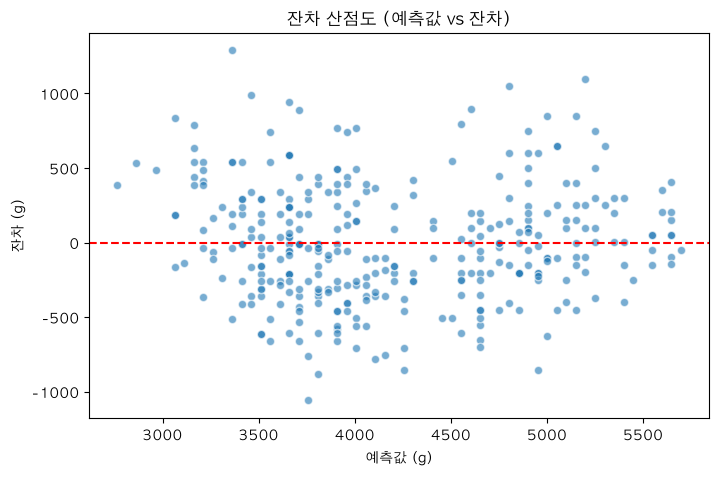

In [26]:
# 문제 5 · Q3
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.scatter(fitted, resid, alpha=0.6, edgecolor='white')   # 펭귄 1마리 = 점 1개
plt.axhline(0, color='red', linestyle='--')                 # 잔차 0 기준선

plt.title('잔차 산점도 (예측값 vs 잔차)')
plt.xlabel('예측값 (g)')
plt.ylabel('잔차 (g)')
plt.show()

### Q4 · 등분산성을 숫자로 검정해 봅시다

- **브루쉬-페이건 검정**으로 등분산성을 확인하세요.

- H₀는 "등분산이다"입니다. p-값이 0.05보다 작으면 이분산을 의심합니다.

- 판정 결과를 문장으로 함께 출력하세요.

- `💡 힌트` `het_breuschpagan(잔차, model.model.exog)`는
  `(LM통계량, LM p-값, F통계량, F p-값)`을 돌려줍니다.

In [27]:
# 문제 5 · Q4
from statsmodels.stats.diagnostic import het_breuschpagan

lm_stat, lm_p, f_stat, f_p = het_breuschpagan(resid, model.model.exog)

alpha = 0.05

print(f"LM 통계량 = {lm_stat:.4f}, LM p-value = {lm_p:.4f}")
print(f"F  통계량 = {f_stat:.4f}, F  p-value = {f_p:.4f}")
print()

if lm_p < alpha:
    print("→ p-value < 0.05 이므로 귀무가설(등분산)을 기각한다.")
    print("→ 이분산이 의심된다. p-값과 신뢰구간을 그대로 믿기 어렵다.")
else:
    print("→ p-value ≥ 0.05 이므로 귀무가설(등분산)을 기각하지 못한다.")
    print("→ 이분산의 증거가 없다. 등분산 가정에 큰 문제가 없다.")

LM 통계량 = 2.1579, LM p-value = 0.1418
F  통계량 = 2.1589, F  p-value = 0.1427

→ p-value ≥ 0.05 이므로 귀무가설(등분산)을 기각하지 못한다.
→ 이분산의 증거가 없다. 등분산 가정에 큰 문제가 없다.


### Q5 · 문제가 있는 모형과 나란히 비교해 봅시다

- **비교군**으로 `body_mass_g ~ bill_length_mm` 모형을 적합해 `model_bill`로 저장하세요.

- 두 모형의 잔차 산점도를 **나란히** 그리세요.

- 두 모형의 브루쉬-페이건 p-값을 **함께 출력**해 비교하세요.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))`로 두 그림을 옆으로 배치할 수 있습니다.

[우리 모형: 날개 길이 → 몸무게]
  R² = 0.7590, BP p-value = 1.42e-01
  → p ≥ 0.05 : 등분산 기각 못 함 → 큰 문제 없음
[비교군: 부리 길이 → 몸무게]
  R² = 0.3542, BP p-value = 9.95e-19
  → p < 0.05 : 등분산 기각 → 이분산 의심


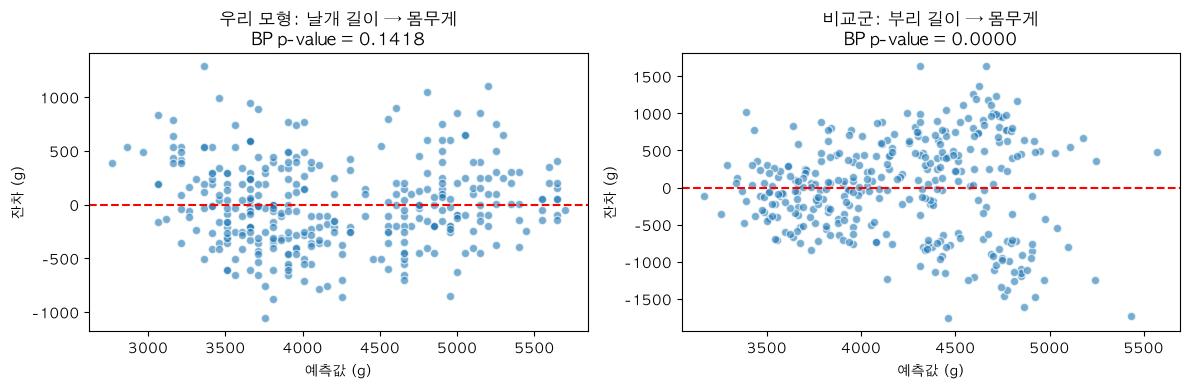

In [28]:
# 문제 5 · Q5
import statsmodels.formula.api as smf
import matplotlib.pyplot as plt
from statsmodels.stats.diagnostic import het_breuschpagan

# 1) 비교군 모형 적합
model_bill = smf.ols(formula='body_mass_g ~ bill_length_mm', data=penguins_cleaned).fit()

# 2) 두 모형을 이름표와 함께 묶기
models = {
    '우리 모형: 날개 길이 → 몸무게': model,
    '비교군: 부리 길이 → 몸무게': model_bill,
}

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

for i, (name, m) in enumerate(models.items()):
    # 브루쉬-페이건 p-값
    bp_p = het_breuschpagan(m.resid, m.model.exog)[1]

    # 잔차 산점도
    ax[i].scatter(m.fittedvalues, m.resid, alpha=0.6, edgecolor='white')
    ax[i].axhline(0, color='red', linestyle='--')
    ax[i].set_title(f'{name}\nBP p-value = {bp_p:.4f}')
    ax[i].set_xlabel('예측값 (g)')
    ax[i].set_ylabel('잔차 (g)')

    # 결과 출력
    print(f"[{name}]")
    print(f"  R² = {m.rsquared:.4f}, BP p-value = {bp_p:.2e}")
    if bp_p < 0.05:
        print("  → p < 0.05 : 등분산 기각 → 이분산 의심")
    else:
        print("  → p ≥ 0.05 : 등분산 기각 못 함 → 큰 문제 없음")

plt.tight_layout()
plt.show()

### Q6 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 우리 회귀모형을 보고서에 어떻게 적을지 **한 문장**으로 쓰세요.

- **기울기 + 유의성 + 설명력 + 진단 결과**를 모두 담아 보세요.

### Q6 · 보고 문장 정리

펭귄 342마리를 대상으로 날개 길이로 몸무게를 설명하는 단순회귀분석 결과, 날개 길이가 1mm 길어질 때 몸무게는 평균 약 **49.69g** 증가하였으며(95% 신뢰구간 46.70~52.67g), 이는 **통계적으로 유의**하였다(p < 0.001). 이 모형은 몸무게 변동의 약 **75.9%를 설명**하였고(R² = 0.759), 브루쉬-페이건 검정에서 **이분산의 증거가 나타나지 않아**(p = 0.142) 등분산 가정에 큰 문제는 없었다. 단, 데이터에 세 종이 섞여 있어 **종에 따라 관계가 달라질 수 있으며**, 이 결과는 상관관계를 보여줄 뿐 **날개 길이가 몸무게의 원인임을 뜻하지는 않는다.**

| 요소 | 내용 | 근거 |
|---|---|---|
| 기울기 | 날개 1mm당 몸무게 평균 약 49.69g 증가 (95% 신뢰구간 46.70~52.67g) | 회귀 결과표 `coef` |
| 유의성 | p < 0.001 → 귀무가설(기울기 = 0) 기각 | 회귀 결과표 `P>\|t\|` |
| 설명력 | 몸무게 변동의 약 75.9% 설명 | `R-squared` = 0.759 |
| 진단 결과 | 이분산의 증거 없음 → 등분산 가정에 큰 문제 없음 | 브루쉬-페이건 p = 0.142 |
| 한계 | 종이 섞여 있음, 인과관계는 알 수 없음 | 문제 1(심슨의 역설), 7.3-⑤ |

### 💬 정리 · 결과를 말로 설명해 보기

- Q3·Q4에서 우리 모형의 잔차는 어떤 상태였나요? 이 결과를 근거로 문제 3·4의 해석을 신뢰할 수 있을까요?

- Q5의 두 잔차 산점도는 어떻게 달랐나요? 비교군에서 관찰된 모양을 강의에서 배운 용어로 무엇이라 부르나요?

- 비교군처럼 등분산성이 깨졌을 때, **잘못된 것은 기울기 값 자체인가요, 아니면 그 값의 통계적 해석인가요?**

- R²가 1이 아니라는 것은 설명되지 않은 변동이 남아 있다는 뜻입니다. `penguins` 안에서 몸무게에 영향을 줄 만한데 우리 모델이 놓치고 있는 변수는 무엇일까요?

- 그 변수들을 모델에 함께 넣으려면 어떤 분석이 필요할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 7장은 이렇게 적었습니다 — _"파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 통계적 해석(유의성·신뢰구간)과 예측 결과를 신뢰할 수 없다는 의미"_. 세 번째 질문의 답이 여기 있습니다.

- 비교군의 잔차가 퍼지는 모양을 강의의 3케이스 그림(정규성 O·등분산 O / X·O / O·X)과 맞춰 보세요.

- 놓친 변수 후보는 문제 1의 그림에 이미 있습니다. 그 변수를 모델에 함께 넣는 분석의 이름은 다음 8장의 제목입니다.

</details>

### 💬 정리 · 결과를 말로 설명해 보기

**1. 우리 모형의 잔차 상태와 문제 3·4 해석의 신뢰성**

- **Q3 (잔차 산점도)**: 잔차가 0 기준선 위아래로 고르게 흩어져 있고, 예측값이 작은 쪽과 큰 쪽 모두 약 ±1000g 안쪽에 비슷한 폭으로 퍼진 **띠 모양**이었다. 깔때기 모양은 보이지 않았다.
- **Q4 (브루쉬-페이건 검정)**: p = 0.142로 0.05보다 커서 귀무가설(등분산)을 **기각하지 못했다**. 이분산의 증거가 없다.
- 따라서 등분산 가정에 큰 문제가 없으므로, 문제 3·4에서 구한 **기울기의 p-값과 신뢰구간 해석은 신뢰할 수 있다.**
- 다만 예측값 4400~4500g 부근에 빈 구간이 있고 작은 쪽 잔차가 대부분 양수인 것으로 보아, **종이 섞여 생긴 약한 패턴**은 남아 있다.

**2. Q5 두 잔차 산점도의 차이와 비교군 모양의 이름**

| 구분 | 우리 모형 (날개 길이) | 비교군 (부리 길이) |
|---|---|---|
| 잔차 모양 | 고른 **띠 모양** | 오른쪽으로 갈수록 벌어지는 **깔때기 모양** |
| 잔차 범위 | 약 ±1000g | 약 ±1700g |
| BP p-value | 0.142 | 9.95e-19 |
| 판정 | 등분산 | **이분산** |

- 비교군에서 관찰된 모양은 **이분산성(Heteroscedasticity)**이다.
- 강의의 세 그림 중 **오른쪽 그림(정규성 O · 등분산 X)**에 해당한다. x(예측값)가 커질수록 오차의 분산도 커지는 경우다.
- 또한 예측값이 큰 쪽에서 잔차가 위아래 두 무리로 갈라졌는데, 부리 길이가 비슷해도 **종에 따라 몸무게가 크게 다르기** 때문으로 보인다.

**3. 등분산성이 깨졌을 때 잘못된 것은 기울기 값인가, 통계적 해석인가?**

- **기울기 값 자체가 잘못된 것은 아니다.** 최소제곱법으로 계산한 a, b는 그대로 "차이² 합이 가장 작은 직선"이다.
- 잘못되는 것은 **그 값의 통계적 해석**이다.
  - 기울기의 **p-값**
  - **신뢰구간**
  - 특히 오차가 큰 구간에서의 **예측 결과**
- p-값과 신뢰구간은 "오차가 어디서나 같은 폭으로 퍼져 있다"고 가정하고 계산하기 때문에, 이 가정이 깨지면 계산 결과를 그대로 믿기 어렵다.
- 비유하면, 체중계가 고장 난 것이 아니라 **"오차 ±1kg"이라는 설명서를 믿을 수 없는 상태**다.

**4. 우리 모델이 놓치고 있는 변수**

- R² = 0.759이므로 몸무게 변동의 **약 24.1%는 날개 길이로 설명되지 않는다.**
- `penguins` 데이터 안에서 몸무게에 영향을 줄 만한 변수 후보는 다음과 같다.

| 변수 | 이유 |
|---|---|
| **species (종)** | 문제 1에서 확인했듯이 종마다 기본 덩치가 다르다. Gentoo는 다른 종보다 훨씬 무겁다. |
| **sex (성별)** | 일반적으로 수컷이 암컷보다 무겁다. |
| **island (섬)** | 서식지에 따라 먹이 환경이 다를 수 있다. 다만 섬과 종이 겹쳐 있을 수 있어 주의가 필요하다. |
| bill_length_mm, bill_depth_mm | 부리 크기도 몸집과 관련이 있을 수 있다. |

- 특히 **종**은 날개 길이와 몸무게 **둘 다에 영향을 주는 교란변수**일 가능성이 크다.

**5. 그 변수들을 함께 넣으려면?**

- 설명변수를 여러 개 넣는 **다중회귀분석(Multiple Regression)**이 필요하다.
  - 예: `body_mass_g ~ flipper_length_mm + species + sex`
- 다중회귀를 쓰면 종과 성별의 영향을 따로 떼어 놓고, **날개 길이만의 효과**를 더 정확하게 볼 수 있다.
- 주의할 점
  - 변수를 늘리면 R²는 항상 올라가므로 **조정 R²**로 비교해야 한다.
  - 의미 없는 변수, 원인과 결과 사이에 끼어 있는 변수, 서로 거의 같은 변수는 넣지 않아야 한다.

**✅ 배운 점**

- 기울기가 유의해도 **R²와 잔차 진단까지 확인**해야 보고할 수 있다.
- 잔차가 **띠 모양**이면 해석을 믿을 수 있고, **깔때기 모양(이분산성)**이면 p-값과 신뢰구간을 믿기 어렵다.
- 등분산성이 깨져도 **기울기 값은 그대로**지만, **통계적 해석**을